In [31]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import itertools
from tqdm import tqdm
import math

In [32]:
def gaussian_mutation(individual, mutation_rate=0.05, sigma=0.1):
    mutated = individual.copy()
    mask = np.random.rand(len(mutated)) < mutation_rate
    
    mutated[mask] += np.random.normal(0, sigma, size=np.sum(mask))
    return mutated

def single_point_crossover(parent1, parent2):
    k = np.random.randint(1, len(parent1))
    
    child1 = np.concatenate([parent1[:k], parent2[k:]])
    child2 = np.concatenate([parent2[:k], parent1[k:]])
    return child1, child2

In [33]:
def rank_selection(combined_population, combined_scores, pop_size):
    # łączymy rodziców i dzieci, sortujemy i ucinamy do rozmiaru populacji - selekcja rankingowa
    sorted_indices = np.argsort(combined_scores)
    best_indices = sorted_indices[:pop_size]

    population = combined_population[best_indices]
    scores = combined_scores[best_indices]    

    return population, scores

def tournament_selection(population, scores, pop_size, k=3):
    new_population = []
    new_scores = []
    
    total_pool_size = len(population)
    
    for _ in range(pop_size):
        participants_idx = np.random.choice(total_pool_size, size=k, replace=False)
        winner_idx = participants_idx[np.argmin(scores[participants_idx])]
        
        new_population.append(population[winner_idx].copy())
        new_scores.append(scores[winner_idx])
        
    return np.array(new_population), np.array(new_scores)


def roulette_wheel_selection(population, scores, pop_size):
    # elitaryzm - najlepszy osobnik przechodzi
    best_idx = np.argmin(scores)
    elite_individual = population[best_idx].copy()
    elite_score = scores[best_idx]

    worst_score = np.max(scores)
    fitness = worst_score - scores + 1e-6 
    
    probabilities = fitness / np.sum(fitness)
    
    total_pool_size = len(population)
    selected_indices = np.random.choice(total_pool_size, size=pop_size-1, p=probabilities)
    
    new_population = population[selected_indices].copy()
    new_scores = scores[selected_indices].copy()

    final_population = np.vstack((elite_individual, new_population))
    final_scores = np.append(elite_score, new_scores)
    
    return final_population, final_scores

In [34]:
class EvolutionaryAlgorithm:
    def __init__(self, objective_func, mutation_op, crossover_op, selection_op, pop_size=100, num_dimensions=5, bounds=(-5.12, 5.12), crossover_prob=0.8, mutation_prob=0.1):
        self.objective_func = objective_func
        self.mutation_op = mutation_op
        self.crossover_op = crossover_op
        self.selection_op = selection_op
        self.pop_size = pop_size
        self.num_dimensions = num_dimensions
        self.bounds = bounds

        self.crossover_prob = crossover_prob
        self.mutation_prob = mutation_prob

        # Inicjalizacja populacji - losowanie z rozkładu jednostajnego z wybranego zakresu
        low, high = self.bounds
        self.population = np.random.uniform(low, high, size=(pop_size, num_dimensions))
        
    def train(self, generations=1000):
        scores = np.array([self.objective_func(ind) for ind in self.population])
        history_best = []
        history_all = []

        # warunek stopu to dana liczba iteracji
        for gen in range(generations):
            children = []

            # KRZYŻOWANIE
            # losowe parowanie
            indices = np.arange(self.pop_size)
            np.random.shuffle(indices)

            for i in range(0, self.pop_size - 1, 2):
                parent1 = self.population[indices[i]]
                parent2 = self.population[indices[i+1]]
                
                if np.random.rand() < self.crossover_prob:
                    child1, child2 = self.crossover_op(parent1, parent2)
                else:
                    child1, child2 = parent1.copy(), parent2.copy()
                    
                children.extend([child1, child2])

            # MUTACJA
            mutated_children = []
            for child in children:
                if np.random.rand() < self.mutation_prob:
                    mutated_children.append(self.mutation_op(child))
                else:
                    mutated_children.append(child)
            
            mutated_children = np.array(mutated_children)

            # EWALUACJA
            children_scores = np.array([self.objective_func(c) for c in mutated_children])

            # SELEKCJA
            combined_population = np.vstack((self.population, mutated_children))
            combined_scores = np.concatenate((scores, children_scores))
            self.population, scores = self.selection_op(combined_population, combined_scores, self.pop_size)

            best_current_score = np.min(scores)
            avg_current_score = np.mean(scores)
            
            history_best.append(best_current_score)
            history_all.append(scores.copy())
        
        best_idx = np.argmin(scores)
        best_individual = self.population[best_idx]
        best_score = scores[best_idx]
        
        return best_individual, best_score, history_best, history_all

In [35]:
def plot(ax, history_all, hist_best, title="Wizualizacja całej populacji", show_ylabel=True):
    generations = len(history_all)
    
    for gen in range(generations):
        scores = history_all[gen]
        x_values = [gen] * len(scores)
        ax.scatter(x_values, scores, color='steelblue', alpha=0.1, s=15, edgecolors='none')

    ax.plot(hist_best, color='black', linewidth=1.5, label='Najlepszy wynik')

    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Generacja", fontsize=12)
    
    if show_ylabel:
        ax.set_ylabel("Wartość funkcji celu", fontsize=12)
        
    ax.legend(fontsize=12)
    ax.set_yscale('log')
    
    ax.grid(True, alpha=0.3)

In [36]:
def run_grid_search(objective_func, bounds, num_dimensions, param_grid):
    keys = param_grid.keys()
    combinations = list(itertools.product(*param_grid.values()))
    
    results_list = []
    all_histories = []

    ordered_selection_names = [op.__name__ for op in param_grid['selection_op']]
    
    grouped_histories = {name: [] for name in ordered_selection_names}
            
    for combo in tqdm(combinations, desc="Postęp Grid Search", unit="test"):
        params = dict(zip(keys, combo))
        selection_name = params['selection_op'].__name__
        
        ea = EvolutionaryAlgorithm(
            objective_func=objective_func,
            mutation_op=gaussian_mutation,
            crossover_op=single_point_crossover,
            selection_op=params['selection_op'],
            pop_size=params['pop_size'],
            num_dimensions=num_dimensions,
            bounds=bounds,
            crossover_prob=params['crossover_prob'],
            mutation_prob=params['mutation_prob']
        )
        
        best_solution, best_score, hist_best, hist_all = ea.train(generations=params['generations'])
        
        results_list.append({
            'Selection': selection_name,
            'Pop Size': params['pop_size'],
            'Cross Prob': params['crossover_prob'],
            'Mut Prob': params['mutation_prob'],
            'Best Score': best_score,
            'Best Solution': np.round(best_solution, 3)
        })
        
        grouped_histories[selection_name].append({
            'score': best_score,
            'hist_best': hist_best,
            'hist_all': hist_all,
            'title': f"{selection_name}\nPop={params['pop_size']}, Cr={params['crossover_prob']}, Mut={params['mutation_prob']}\nWynik: {best_score:.4f}"
        })
            
    for sel_name in ordered_selection_names:
        grouped_histories[sel_name].sort(key=lambda x: x['score'])
        grouped_histories[sel_name] = grouped_histories[sel_name][:3]
    
    cols = len(ordered_selection_names)
    rows = max((len(v) for v in grouped_histories.values()), default=1)
    
    fig, axes = plt.subplots(rows, cols, figsize=(7 * cols, 5 * rows))
    
    if rows == 1 and cols == 1:
        axes = np.array([[axes]])
    elif rows == 1:
        axes = np.expand_dims(axes, axis=0)
    elif cols == 1:
        axes = np.expand_dims(axes, axis=1)
        
    for col, sel_name in enumerate(ordered_selection_names):
        histories_for_column = grouped_histories[sel_name]
        
        for row in range(rows):
            ax = axes[row, col]
            
            if row < len(histories_for_column):
                data = histories_for_column[row]
                show_y = (col == 0)
                plot(ax, data['hist_all'], data['hist_best'], title=data['title'], show_ylabel=show_y)
            else:
                ax.axis('off')
            
    plt.tight_layout()
    plt.show()
        
    results_df = pd.DataFrame(results_list)
    return results_df.sort_values(by='Best Score').reset_index(drop=True)

# Funkcja $x^2+y^2+2z^2$

In [37]:
def function_3d(x):
    return x[0]**2 + x[1]**2 + 2*x[2]**2

Postęp Grid Search: 100%|██████████| 81/81 [00:12<00:00,  6.38test/s]


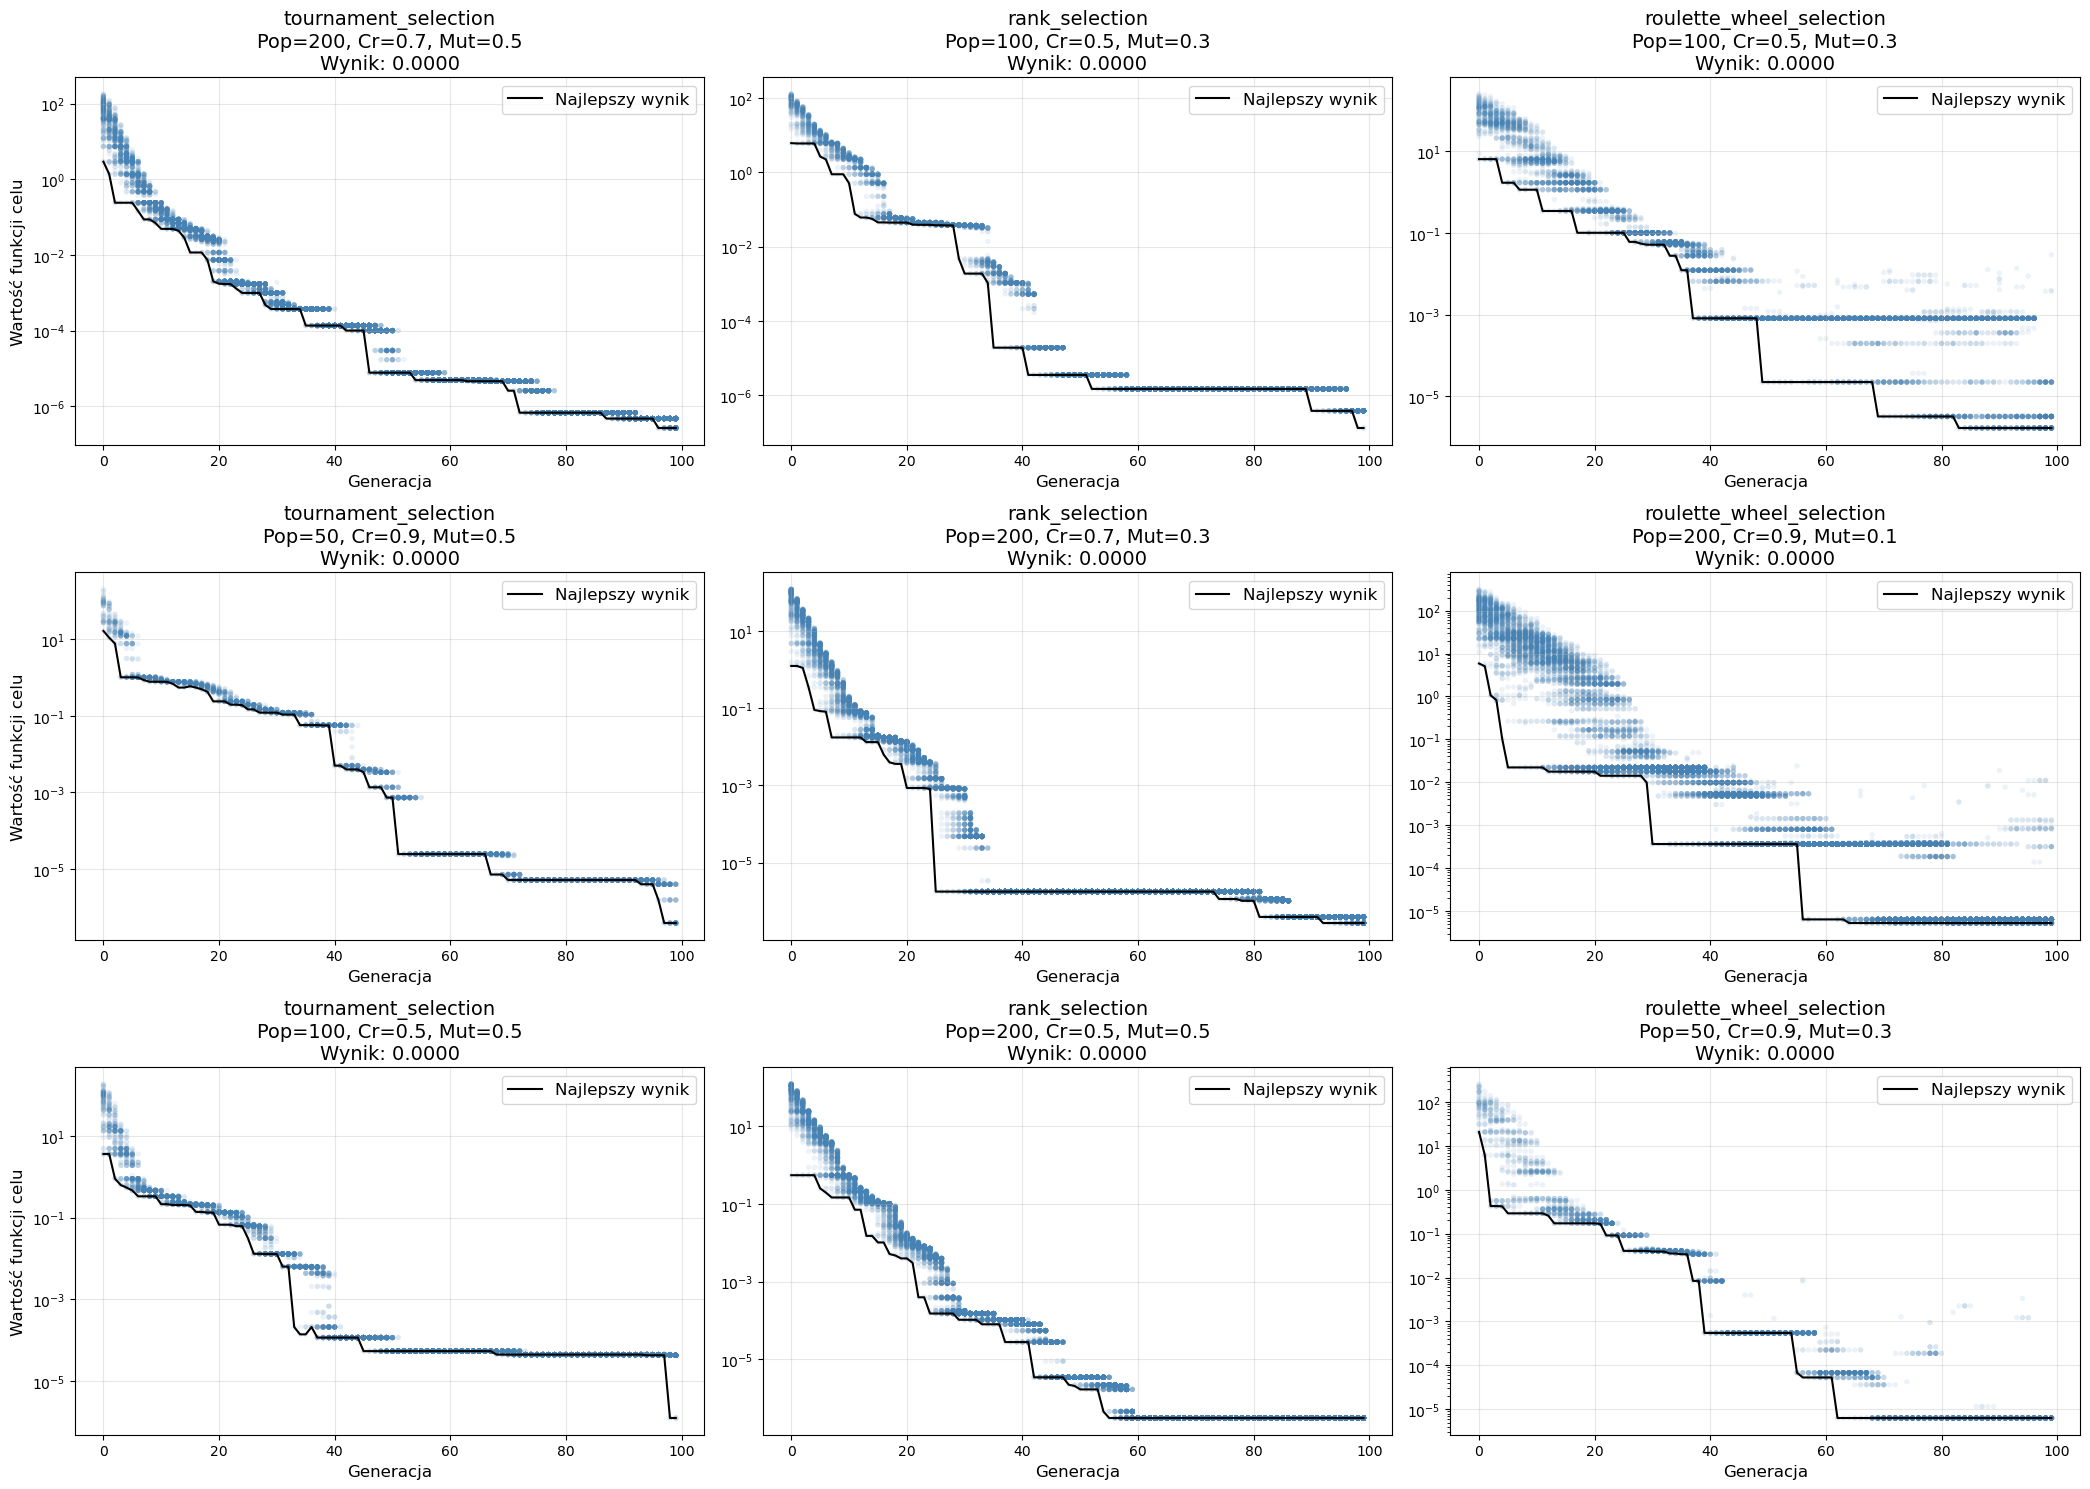

,Selection,Pop Size,Cross Prob,Mut Prob,Best Score,Best Solution
0,rank_selection,100,0.5,0.3,1.331530e-07,"[0.0, 0.0, 0.0]"
1,tournament_selection,200,0.7,0.5,2.640531e-07,"[-0.001, 0.0, 0.0]"
2,rank_selection,200,0.7,0.3,2.719149e-07,"[-0.0, 0.0, 0.0]"
3,rank_selection,200,0.5,0.5,3.126273e-07,"[-0.0, 0.0, -0.0]"
4,tournament_selection,50,0.9,0.5,3.917718e-07,"[0.0, -0.0, 0.0]"
...,...,...,...,...,...,...
76,rank_selection,50,0.7,0.1,9.294014e-02,"[0.021, 0.304, 0.006]"
77,roulette_wheel_selection,50,0.7,0.1,1.204208e-01,"[-0.34, -0.044, -0.037]"
78,rank_selection,50,0.5,0.1,1.770165e-01,"[0.041, 0.418, -0.012]"
79,tournament_selection,50,0.9,0.1,2.634328e-01,"[0.115, -0.491, -0.066]"


In [38]:
param_grid_3d = {
    'selection_op': [tournament_selection, rank_selection, roulette_wheel_selection],
    'pop_size': [50, 100, 200],
    'crossover_prob': [0.5, 0.7, 0.9],
    'mutation_prob': [0.1, 0.3, 0.5],
    'generations': [100]
}

results_table = run_grid_search(
    objective_func=function_3d, 
    bounds=(-10.0, 10.0), 
    num_dimensions=3, 
    param_grid=param_grid_3d
)

results_table

# Funkcja Rastrigina

In [39]:
def rastrigin(x, A=10):
    x = np.array(x)
    n = len(x)
    return A * n + np.sum(x**2 - A * np.cos(2 * np.pi * x))

Postęp Grid Search: 100%|██████████| 81/81 [00:17<00:00,  4.54test/s]


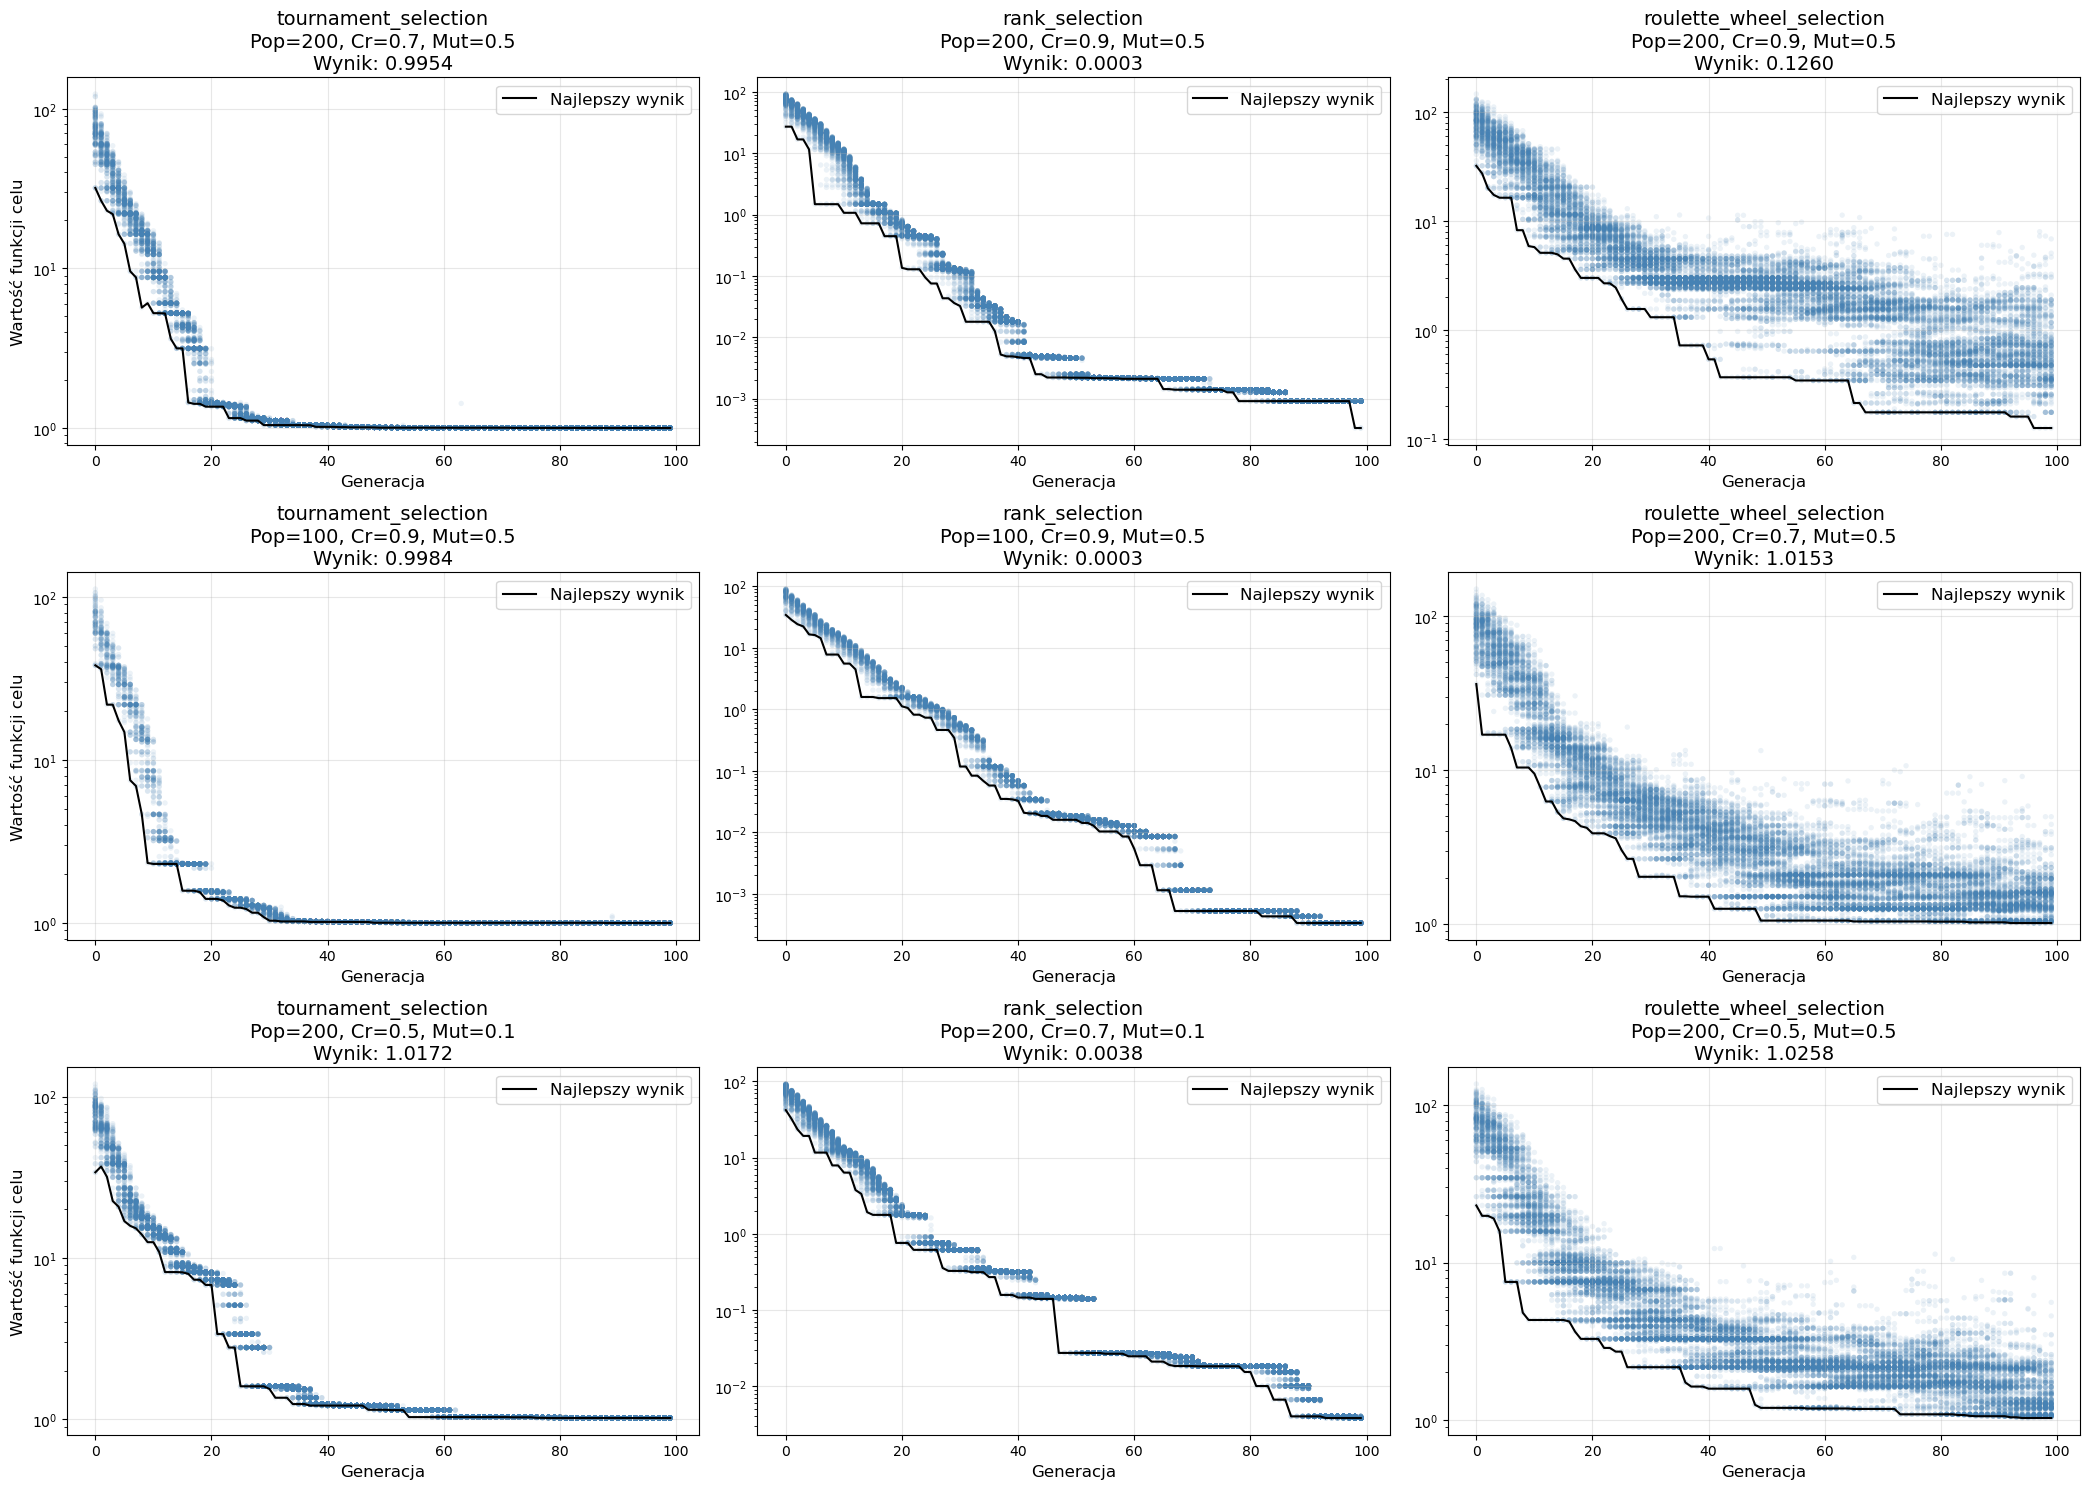

,Selection,Pop Size,Cross Prob,Mut Prob,Best Score,Best Solution
0,rank_selection,200,0.9,0.5,0.000332,"[-0.0, 0.0, -0.0, -0.001, 0.001]"
1,rank_selection,100,0.9,0.5,0.000337,"[0.0, 0.001, 0.0, 0.0, 0.0]"
2,rank_selection,200,0.7,0.1,0.003819,"[-0.003, 0.001, -0.003, 0.0, -0.001]"
3,roulette_wheel_selection,200,0.9,0.5,0.126010,"[-0.004, 0.005, 0.007, 0.006, -0.023]"
4,rank_selection,200,0.5,0.5,0.995249,"[0.0, -0.995, 0.001, 0.0, 0.0]"
...,...,...,...,...,...,...
76,tournament_selection,50,0.7,0.3,8.963118,"[-0.004, -1.99, 0.999, -1.99, -0.004]"
77,rank_selection,50,0.7,0.1,10.027913,"[1.973, -0.995, -0.001, -2.0, 0.996]"
78,tournament_selection,100,0.7,0.1,10.992666,"[-1.006, -1.999, 1.99, -0.999, -0.991]"
79,roulette_wheel_selection,50,0.5,0.1,11.134264,"[-1.981, -1.02, 0.989, 0.987, 2.002]"


In [40]:
param_grid_rastrigin = {
    'selection_op': [tournament_selection, rank_selection, roulette_wheel_selection],
    'pop_size': [50, 100, 200],
    'crossover_prob': [0.5, 0.7, 0.9],
    'mutation_prob': [0.1, 0.3, 0.5],
    'generations': [100]
}

results_table = run_grid_search(
    objective_func=rastrigin, 
    bounds=(-5.12, 5.12), 
    num_dimensions=5, 
    param_grid=param_grid_rastrigin
)

results_table